# Part B: Programming (Python, CPU only, keep it simple)

## Task 1: Measure latency vs batch size

- Load a small pretrained model on CPU (e.g. distilbert-base-uncased or distilgpt2 from HuggingFace, both are light enough for CPU)
- Run inference with batch sizes 1, 2, 4, 8 (kept small since it's CPU)
- Measure and print time taken per batch
- Plot batch size vs total time, and batch size vs time-per-sample
- Write 2-3 lines on what pattern they observe

In [1]:
import time
import os
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
model = AutoModel.from_pretrained("distilbert-base-uncased")
model.eval()

C:\Users\TEJAL DADAJI PAGAR\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\TEJAL DADAJI PAGAR\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\TEJAL DADAJI PAGAR\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python 

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

In [2]:
sentences = ["I am learning how to measure the speed of a model."] * 8
batch_sizes = [1, 2, 4, 8]
total_times = []
per_sample_times = []

with torch.no_grad():
    model(**tokenizer(sentences[:1], return_tensors="pt"))

for bs in batch_sizes:
    inputs = tokenizer(sentences[:bs], return_tensors="pt", padding=True)
    start = time.time()
    with torch.no_grad():
        for _ in range(5):
            model(**inputs)
    t = (time.time() - start) / 5
    total_times.append(t)
    per_sample_times.append(t / bs)
    print("batch size", bs, "| time per batch:", round(t, 4), "s | time per sample:", round(t / bs, 4), "s")

batch size 1 | time per batch: 0.0632 s | time per sample: 0.0632 s
batch size 2 | time per batch: 0.0827 s | time per sample: 0.0413 s
batch size 4 | time per batch: 0.1445 s | time per sample: 0.0361 s
batch size 8 | time per batch: 0.2772 s | time per sample: 0.0347 s


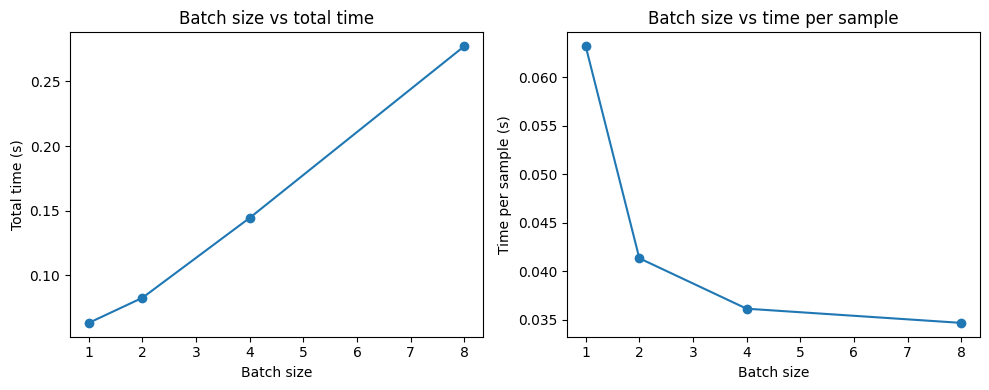

In [3]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(batch_sizes, total_times, marker="o")
plt.xlabel("Batch size")
plt.ylabel("Total time (s)")
plt.title("Batch size vs total time")

plt.subplot(1, 2, 2)
plt.plot(batch_sizes, per_sample_times, marker="o")
plt.xlabel("Batch size")
plt.ylabel("Time per sample (s)")
plt.title("Batch size vs time per sample")

plt.tight_layout()
plt.show()

**Observation:** The total time for a batch goes up as the batch size increases, because the model has more sentences to process. But the time per sample goes down as the batch size increases. So processing sentences together in a batch is cheaper per sentence than processing them one by one.

## Task 2: Implement basic quantization (CPU friendly)

- Load the same small model
- Quantize it using torch.quantization.quantize_dynamic (this works on CPU, no GPU needed)
- Compare model size before/after quantization (use torch.save and check file size, or sys.getsizeof on state dict)
- Run a few sample inputs and compare inference time before vs after
- Write 2-3 lines on the speed/size difference observed

In [4]:
quantized_model = torch.quantization.quantize_dynamic(model, {torch.nn.Linear}, dtype=torch.qint8)
quantized_model.eval()

C:\Users\TEJAL DADAJI PAGAR\AppData\Local\Temp\ipykernel_6728\3836953314.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.quantization.quantize_dynamic(model, {torch.nn.Linear}, dtype=torch.qint8)
C:\Users\TEJAL DADAJI PAGAR\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\ao\nn\quantized\modules\utils.py:72: UserWarning: torch.q

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): DynamicQuantizedLinear(in_features=768, out_features=768, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
          (k_lin): DynamicQuantizedLinear(in_features=768, out_features=768, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
          (v_lin): DynamicQuantizedLinear(in_features=768, out_features=768, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
          (out_lin): DynamicQuantizedLinear(in_features=768, out_features=768, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
          (dropout): Dropout(p=0.1, inplace=False)
        )
  

In [5]:
def get_size(m):
    torch.save(m.state_dict(), "temp.pth")
    size = os.path.getsize("temp.pth") / (1024 * 1024)
    os.remove("temp.pth")
    return size

print("Size before quantization:", round(get_size(model), 2), "MB")
print("Size after quantization:", round(get_size(quantized_model), 2), "MB")

Size before quantization: 253.18 MB
Size after quantization: 131.71 MB


In [6]:
inputs = tokenizer(sentences[:4], return_tensors="pt", padding=True)

def get_time(m):
    with torch.no_grad():
        m(**inputs)
    start = time.time()
    with torch.no_grad():
        for _ in range(10):
            m(**inputs)
    return (time.time() - start) / 10

print("Time before quantization:", round(get_time(model), 4), "s")
print("Time after quantization:", round(get_time(quantized_model), 4), "s")

Time before quantization: 0.1518 s
Time after quantization: 0.0854 s


**Observation:** After quantization the model size became smaller, roughly half of the original, because the Linear layers were converted from 32-bit floats to 8-bit integers. The quantized model also ran faster on CPU for the same inputs.